# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import ExtraTreesRegressor

# Use the same folds throughout the Ames analyses so the RMSE values are comparable.
cv = KFold(n_splits=5, shuffle=True, random_state=5544)


## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [2]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


In [3]:
def make_preprocessor(data, features, scale_numeric=False):
    """Impute missing values and one-hot encode categorical predictors."""
    numeric_features = data[features].select_dtypes(include=np.number).columns.tolist()
    categorical_features = [feature for feature in features if feature not in numeric_features]

    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))

    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('one_hot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ])

def rmse_cv(model, X, y):
    """Return five-fold CV RMSE values (positive, in dollars)."""
    scores = cross_val_score(model, X, y, cv=cv,
                             scoring='neg_root_mean_squared_error', n_jobs=-1)
    return -scores

y_ames = df_ames['SalePrice']


1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [4]:
# I chose sets that progressively add common drivers of sale price: size, quality,
# age, basement/garage capacity, and location.
feature_sets = {
    '1. Original five': ['Gr Liv Area', 'Bedroom AbvGr', 'Full Bath', 'Half Bath', 'Neighborhood'],
    '2. Size and quality': ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Total Bsmt SF', 'Garage Cars'],
    '3. Size, quality, and location': ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Total Bsmt SF', 'Garage Cars', 'Neighborhood'],
    '4. Expanded house characteristics': ['Gr Liv Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add',
                                         'Total Bsmt SF', '1st Flr SF', 'Garage Area', 'Full Bath', 'Fireplaces'],
    '5. Expanded characteristics and location': ['Gr Liv Area', 'Overall Qual', 'Overall Cond', 'Year Built',
                                                  'Year Remod/Add', 'Total Bsmt SF', '1st Flr SF', 'Garage Area',
                                                  'Full Bath', 'Fireplaces', 'Neighborhood', 'Kitchen Qual']
}

part1_results = []
for name, features in feature_sets.items():
    model = Pipeline([
        ('preprocess', make_preprocessor(df_ames, features, scale_numeric=True)),
        ('knn', KNeighborsRegressor(n_neighbors=10))
    ])
    scores = rmse_cv(model, df_ames[features], y_ames)
    part1_results.append({'feature set': name, 'mean CV RMSE': scores.mean(), 'CV RMSE SD': scores.std()})

part1_results = pd.DataFrame(part1_results).sort_values('mean CV RMSE').reset_index(drop=True)
display(part1_results.style.format({'mean CV RMSE': '${:,.0f}', 'CV RMSE SD': '${:,.0f}'}))

best_part1_name = part1_results.loc[0, 'feature set']
best_part1_features = feature_sets[best_part1_name]
print(f"Lowest RMSE: ${part1_results.loc[0, 'mean CV RMSE']:,.0f} using {best_part1_name}.")
print('Features:', ', '.join(best_part1_features))


,feature set,mean CV RMSE,CV RMSE SD
0,5. Expanded characteristics and location,"$28,526","$2,584"
1,4. Expanded house characteristics,"$28,848","$2,626"
2,"3. Size, quality, and location","$30,144","$2,596"
3,2. Size and quality,"$30,325","$2,122"
4,1. Original five,"$39,255","$3,148"


Lowest RMSE: $28,526 using 5. Expanded characteristics and location.
Features: Gr Liv Area, Overall Qual, Overall Cond, Year Built, Year Remod/Add, Total Bsmt SF, 1st Flr SF, Garage Area, Full Bath, Fireplaces, Neighborhood, Kitchen Qual


2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

Best k = 6; estimated CV RMSE = $38,977.


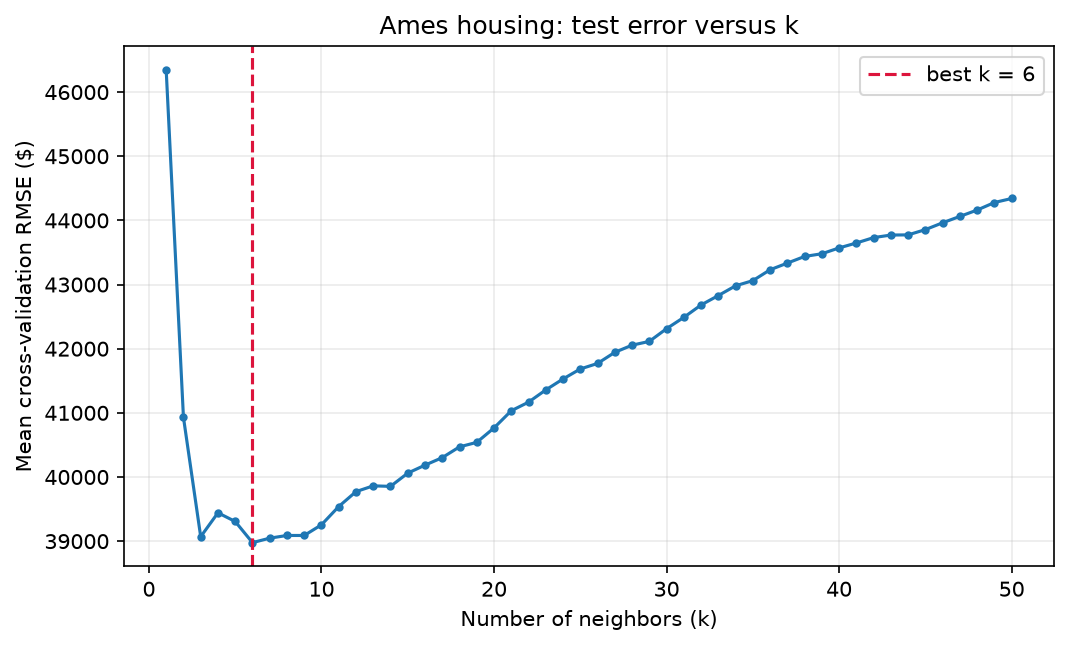

In [5]:

specified_features = ['Gr Liv Area', 'Bedroom AbvGr', 'Full Bath', 'Half Bath', 'Neighborhood']

knn_grid = Pipeline([
    ('preprocess', make_preprocessor(df_ames, specified_features, scale_numeric=True)),
    ('knn', KNeighborsRegressor())
])

grid_k = GridSearchCV(
    knn_grid,
    param_grid={'knn__n_neighbors': list(range(1, 51))},
    scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, return_train_score=False
)
grid_k.fit(df_ames[specified_features], y_ames)

k_results = pd.DataFrame(grid_k.cv_results_)
k_results['RMSE'] = -k_results['mean_test_score']
best_k = grid_k.best_params_['knn__n_neighbors']
print(f"Best k = {best_k}; estimated CV RMSE = ${-grid_k.best_score_:,.0f}.")

plt.figure(figsize=(8, 4.5))
plt.plot(k_results['param_knn__n_neighbors'], k_results['RMSE'], marker='o', markersize=3)
plt.axvline(best_k, color='crimson', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Mean cross-validation RMSE ($)')
plt.title('Ames housing: test error versus k')
plt.legend()
plt.grid(alpha=.25)
plt.show()


3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

,param_knn__n_neighbors,param_knn__metric,RMSE
55,6,manhattan,"$38,644"
56,7,manhattan,"$38,723"
54,5,manhattan,"$38,822"
58,9,manhattan,"$38,856"
57,8,manhattan,"$38,870"
60,11,manhattan,"$38,883"
59,10,manhattan,"$38,883"
53,4,manhattan,"$38,910"
5,6,euclidean,"$38,977"
6,7,euclidean,"$39,047"


Best model with both parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 6}
Estimated CV RMSE: $38,644
Compared with Part 2, allowing the metric to vary changes RMSE by $-333.


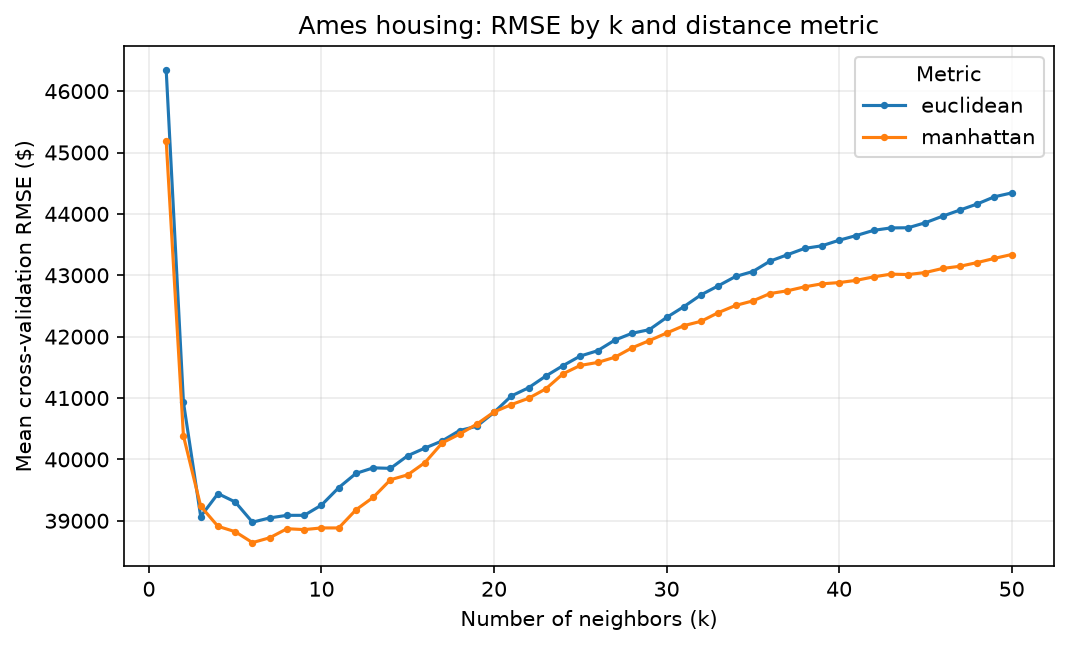

In [6]:
metric_grid = GridSearchCV(
    knn_grid,
    param_grid={
        'knn__n_neighbors': list(range(1, 51)),
        'knn__metric': ['euclidean', 'manhattan']
    },
    scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, return_train_score=False
)
metric_grid.fit(df_ames[specified_features], y_ames)

metric_results = pd.DataFrame(metric_grid.cv_results_)
metric_results['RMSE'] = -metric_results['mean_test_score']
display(metric_results.loc[:, ['param_knn__n_neighbors', 'param_knn__metric', 'RMSE']]
        .sort_values('RMSE').head(10).style.format({'RMSE': '${:,.0f}'}))

best_metric_params = metric_grid.best_params_
print('Best model with both parameters:', best_metric_params)
print(f"Estimated CV RMSE: ${-metric_grid.best_score_:,.0f}")
print(f"Compared with Part 2, allowing the metric to vary changes RMSE by "
      f"${(-metric_grid.best_score_) - (-grid_k.best_score_):,.0f}.")

plt.figure(figsize=(8, 4.5))
for metric, group in metric_results.groupby('param_knn__metric'):
    plt.plot(group['param_knn__n_neighbors'], group['RMSE'], marker='o', markersize=2.5, label=metric)
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Mean cross-validation RMSE ($)')
plt.title('Ames housing: RMSE by k and distance metric')
plt.legend(title='Metric')
plt.grid(alpha=.25)
plt.show()


4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

In [7]:
# I tune k, the distance metric, and whether nearer homes receive more weight.
# The feature list is the strongest set investigated in Part 1.
best_knn_features = best_part1_features
best_knn_pipeline = Pipeline([
    ('preprocess', make_preprocessor(df_ames, best_knn_features, scale_numeric=True)),
    ('knn', KNeighborsRegressor())
])

best_knn_grid = GridSearchCV(
    best_knn_pipeline,
    param_grid={
        'knn__n_neighbors': list(range(2, 31)),
        'knn__metric': ['euclidean', 'manhattan'],
        'knn__weights': ['uniform', 'distance']
    },
    scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1
)
best_knn_grid.fit(df_ames[best_knn_features], y_ames)

best_knn_rmse = -best_knn_grid.best_score_
print('Features:', ', '.join(best_knn_features))
print('Best kNN settings:', best_knn_grid.best_params_)
print(f"Estimated five-fold CV test RMSE: ${best_knn_rmse:,.0f}")


Features: Gr Liv Area, Overall Qual, Overall Cond, Year Built, Year Remod/Add, Total Bsmt SF, 1st Flr SF, Garage Area, Full Bath, Fireplaces, Neighborhood, Kitchen Qual
Best kNN settings: {'knn__metric': 'manhattan', 'knn__n_neighbors': 6, 'knn__weights': 'distance'}
Estimated five-fold CV test RMSE: $26,971


5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?


In [8]:
linear_model = Pipeline([
    ('preprocess', make_preprocessor(df_ames, best_knn_features, scale_numeric=False)),
    ('linear_regression', LinearRegression())
])
linear_scores = rmse_cv(linear_model, df_ames[best_knn_features], y_ames)
linear_rmse = linear_scores.mean()

comparison = pd.DataFrame({
    'model': ['Tuned kNN', 'Linear regression'],
    'mean five-fold CV RMSE': [best_knn_rmse, linear_rmse]
})
display(comparison.style.format({'mean five-fold CV RMSE': '${:,.0f}'}))

if linear_rmse < best_knn_rmse:
    print(f"Linear regression is better by ${best_knn_rmse - linear_rmse:,.0f} in estimated RMSE.")
else:
    print(f"The tuned kNN model is better by ${linear_rmse - best_knn_rmse:,.0f} in estimated RMSE.")


,model,mean five-fold CV RMSE
0,Tuned kNN,"$26,971"
1,Linear regression,"$31,009"


The tuned kNN model is better by $4,039 in estimated RMSE.


## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [9]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


Rows: 10,000; columns: 56


,interest_rate
count,10000.000000
mean,12.427524
std,5.001105
min,5.310000
25%,9.430000
50%,11.980000
75%,15.050000
max,30.940000


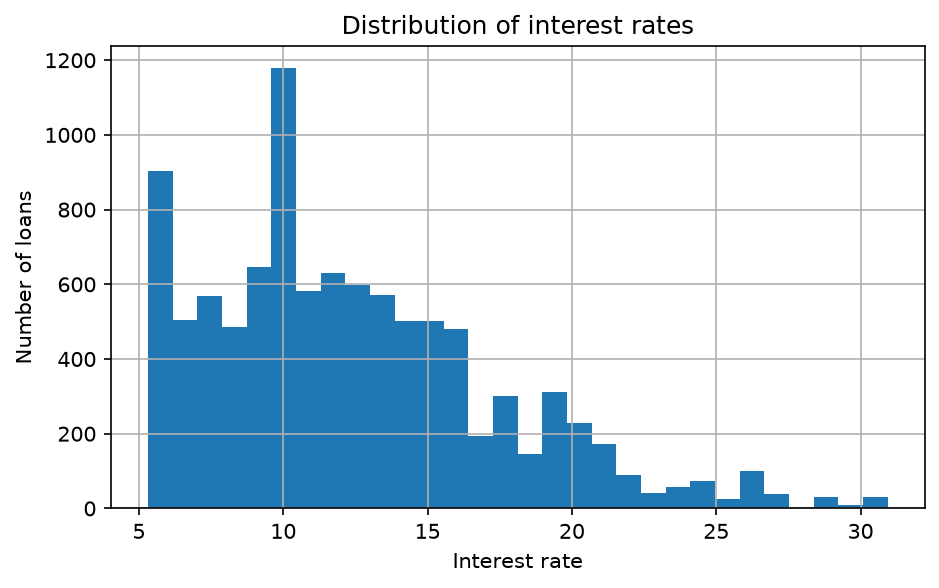

Features used: loan_amount, term, grade, sub_grade, loan_purpose, homeownership, annual_income, verified_income, debt_to_income, delinq_2y, inquiries_last_12m, total_credit_lines, open_credit_lines, total_credit_limit, total_credit_utilized, num_historical_failed_to_pay, months_since_90d_late, current_accounts_delinq, accounts_opened_24m, num_satisfactory_accounts, num_active_debit_accounts, num_mort_accounts, account_never_delinq_percent, public_record_bankrupt, state, application_type


In [ ]:

print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df['interest_rate'].describe().to_frame('interest_rate'))
df['interest_rate'].hist(bins=30, figsize=(7, 4))
plt.title('Distribution of interest rates')
plt.xlabel('Interest rate')
plt.ylabel('Number of loans')
plt.show()

candidate_features = [
    'loan_amount', 'term', 'grade', 'sub_grade', 'loan_purpose', 'homeownership',
    'annual_income', 'verified_income', 'debt_to_income', 'delinq_2y',
    'inquiries_last_12m', 'total_credit_lines', 'open_credit_lines',
    'total_credit_limit', 'total_credit_utilized', 'num_historical_failed_to_pay',
    'months_since_90d_late', 'current_accounts_delinq', 'accounts_opened_24m',
    'num_satisfactory_accounts', 'num_active_debit_accounts', 'num_mort_accounts',
    'account_never_delinq_percent', 'public_record_bankrupt', 'state', 'application_type'
]
loan_features = [feature for feature in candidate_features if feature in df.columns]
print('Features used:', ', '.join(loan_features))

X_loans = df[loan_features]
y_loans = df['interest_rate']
X_train, X_test, y_train, y_test = train_test_split(
    X_loans, y_loans, test_size=0.20, random_state=5544
)

loan_pipeline = Pipeline([
    ('preprocess', make_preprocessor(df, loan_features, scale_numeric=False)),
    ('model', ExtraTreesRegressor(random_state=5544, n_jobs=-1))
])

loan_grid = GridSearchCV(
    loan_pipeline,
    param_grid={
        'model__n_estimators': [350],
        'model__max_features': [0.7, 1.0],
        'model__min_samples_leaf': [1, 2]
    },
    scoring='neg_root_mean_squared_error',
    cv=5, n_jobs=-1
)
loan_grid.fit(X_train, y_train)

loan_predictions = loan_grid.predict(X_test)
loan_test_rmse = mean_squared_error(y_test, loan_predictions, squared=False)
print('Best hyperparameters:', loan_grid.best_params_)
print(f"Best CV RMSE on the training data: ${-loan_grid.best_score_:,.3f}")
print(f"Held-out test RMSE: ${loan_test_rmse:,.3f}")

importance_model = loan_grid.best_estimator_.named_steps['model']
transformed_names = loan_grid.best_estimator_.named_steps['preprocess'].get_feature_names_out()
importance = (pd.DataFrame({'feature': transformed_names, 'importance': importance_model.feature_importances_})
              .sort_values('importance', ascending=False).head(15))
display(importance)
